# Experiment A: Rating-group LDA baseline (Le et al.)

**Paper.** Thien Le, Van-Ho Nguyen, and Thanh Ho (2022), *A Model of Discovering Customer Insights in Tourism Sector: Approach to Vietnamese Reviews Analytics*, DOI: 10.1109/NICS56915.2022.10013410.

**Goal.** Follow the paper's structure on a new Agoda snapshot: divide Vietnamese hotel reviews into Detractors, Passives, and Promoters by overall rating; fit a separate LDA model to each group; search K = 1–6 by C_v coherence; inspect weighted words and real reviews. These are **rating-derived groups, not measured NPS**. A group label alone does not prove the sentiment of an individual topic or sentence.

**Input.** This notebook reads only data/agoda_vi_reviews_preprocessed.csv. It uses lda_text for LDA and review_text_clean for inspection. It does not write another dataset. Run cells in order with the .venv kernel after installing requirements-experiments.txt. Model settings are documented implementation choices where the paper does not provide full hyperparameters.

## 1. Set up a reproducible run

Find the input regardless of whether Jupyter starts in the project root or `notebooks/`. Fix the random seed, K range, number of training passes, and C_v sample size. Charts are embedded in the notebook output; no image files are generated.


In [1]:
import csv
import random
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/agoda_vi_reviews_preprocessed.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Missing preprocessed CSV")
INPUT = ROOT / "data/agoda_vi_reviews_preprocessed.csv"
GROUPS = ("Detractors", "Passives", "Promoters")
COLORS = {"Detractors": "#c44e52", "Passives": "#ddaa33", "Promoters": "#4c9f70"}
K_VALUES = range(1, 7)
SEED, PASSES, ITERATIONS = 42, 2, 40
COHERENCE_SAMPLE, TOP_N = 2500, 15
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Input:", INPUT)
print("K search:", list(K_VALUES), "passes:", PASSES)


Input: /home/tvphuoc/NLP/data/agoda_vi_reviews_preprocessed.csv
K search: [1, 2, 3, 4, 5, 6] passes: 2


## 2. Load and audit the review groups

Each nonempty lda_text is one LDA document. Check columns and group names. The chart shows group size, the denominator for later within-group percentages. A large difference in group sizes can affect topic stability. The examples below show the actual text being analyzed before topic modeling.

Total reviews: 87837 Group sizes: {'Detractors': 18120, 'Passives': 12462, 'Promoters': 57255}


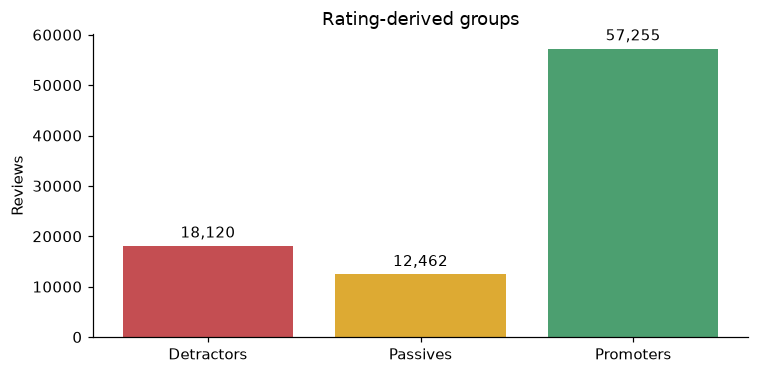


Example reviews by rating-derived group (random, fixed seed):

Detractors:
  rating=6.0: Wifi rất yếu
  rating=4.8: Phòng cũ, giá cao

Passives:
  rating=8.0: Hài lòng vẫn sẽ ở đây mỗi khi đến
  rating=7.2: Đặt phòng có bồn tắm nhận phòng ko có, phòng 4 mà 1 cái giường to 1 cái nhỏ xíu giường đơn ko giống hình quản cáo, lể tân kiếm muốn khùng luôn còn lại ok

Promoters:
  rating=8.8: Tiện lợi, vị tria trong ngõ nhưng dễ tìm, tiện hàng ăn uống cafe, cách Hồ con rùa 500m...
  rating=9.6: Đến Đà Lạt lần này vào thời điểm vắng khách do sạt lở đèo, nên không khí rất nhẹ nhàng :D Khách sạn phục vụ chu đáo!


In [2]:
with INPUT.open("r", encoding="utf-8", newline="") as stream:
    reader = csv.DictReader(stream)
    required = {"hotel_id", "review_id", "label", "lda_text", "review_text_clean"}
    missing = required - set(reader.fieldnames or [])
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    rows = [row for row in reader if row["lda_text"].strip()]
if any(row["label"] not in GROUPS for row in rows):
    raise ValueError("Unexpected rating group")
rows_by_group = {g: [row for row in rows if row["label"] == g] for g in GROUPS}
texts_by_group = {g: [row["lda_text"].split() for row in rows_by_group[g]] for g in GROUPS}
group_sizes = {g: len(rows_by_group[g]) for g in GROUPS}
print("Total reviews:", len(rows), "Group sizes:", group_sizes)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(GROUPS, [group_sizes[g] for g in GROUPS], color=[COLORS[g] for g in GROUPS])
ax.bar_label(bars, labels=[f"{group_sizes[g]:,}" for g in GROUPS], padding=3)
ax.set(ylabel="Reviews", title="Rating-derived groups")
plt.tight_layout(); plt.show()

print("\nExample reviews by rating-derived group (random, fixed seed):")
for g in GROUPS:
    sample_rows = random.Random(SEED).sample(rows_by_group[g], min(2, group_sizes[g]))
    print(f"\n{g}:")
    for row in sample_rows:
        snippet = " ".join(row["review_text_clean"].split())[:230]
        print(f"  rating={row['rating_10']}: {snippet}")


## 3. Build a separate vocabulary for each group

Remove tokens occurring in fewer than 10 group documents or more than 65% of them, then keep at most 5,000 terms. These thresholds reduce rare spelling noise and common words. A document may become empty after this filter; count and exclude it from LDA. Every candidate K within a group uses the same vocabulary and documents.


In [3]:
def prepare_group(token_lists):
    dictionary = Dictionary(token_lists)
    dictionary.filter_extremes(no_below=10, no_above=0.65, keep_n=5000)
    bows = [dictionary.doc2bow(tokens) for tokens in token_lists]
    valid = [(tokens, bow, i) for i, (tokens, bow)
             in enumerate(zip(token_lists, bows)) if bow]
    if len(dictionary) < 20 or len(valid) < 100:
        raise ValueError("Too little vocabulary or too few documents")
    return (dictionary, [t for t, _, _ in valid],
            [b for _, b, _ in valid], [i for _, _, i in valid])

prepared = {g: prepare_group(texts_by_group[g]) for g in GROUPS}
for g in GROUPS:
    dictionary, texts, corpus, indices = prepared[g]
    print(f"{g}: {len(corpus):,} usable documents; {len(dictionary):,} terms; "
          f"{group_sizes[g] - len(corpus):,} empty after vocabulary filtering")


Detractors: 18,066 usable documents; 1,508 terms; 54 empty after vocabulary filtering
Passives: 12,393 usable documents; 956 terms; 69 empty after vocabulary filtering
Promoters: 57,064 usable documents; 1,901 terms; 191 empty after vocabulary filtering


## 4. Train K = 1–6 on each full group and compute C_v coherence

Fit each model on all eligible reviews of its group, with a fixed seed and two passes. Compute coherence on the **same deterministic sample** of at most 2,500 reviews for every K within that group, using the top 15 words. Select the highest score, breaking ties toward the smaller K. Coherence screens candidate models; inspect the topics before interpreting them. This CPU cell may take several minutes.


In [4]:
models, scores, selected = {}, {}, {}
for g in GROUPS:
    dictionary, texts, corpus, indices = prepared[g]
    sample = random.Random(SEED).sample(texts, min(COHERENCE_SAMPLE, len(texts)))
    models[g], scores[g] = {}, {}
    print(f"Training {g} ({len(corpus):,} documents)", flush=True)
    for k in K_VALUES:
        model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                         passes=PASSES, iterations=ITERATIONS, chunksize=2000,
                         random_state=SEED, eval_every=None, minimum_probability=0)
        coherence = CoherenceModel(model=model, texts=sample, dictionary=dictionary,
                                   coherence="c_v", topn=TOP_N, processes=1).get_coherence()
        models[g][k], scores[g][k] = model, float(coherence)
        print(f"  K={k}: C_v={coherence:.4f}", flush=True)
    best = max(K_VALUES, key=lambda k: (scores[g][k], -k))
    selected[g] = (best, models[g][best])
    print(f"Selected {g}: K={best}, C_v={scores[g][best]:.4f}", flush=True)


Training Detractors (18,066 documents)


  K=1: C_v=0.6229


  K=2: C_v=0.6436


  K=3: C_v=0.6211


  K=4: C_v=0.5813


  K=5: C_v=0.5959


... (14 outputs left out)

  K=4: C_v=0.5514


  K=5: C_v=0.5402


  K=6: C_v=0.5897


Selected Promoters: K=6, C_v=0.5897


## 5. Visualize the coherence search

Read each curve **within its own group**. The vocabularies and documents differ between groups, so a score gap between groups is not a sentiment comparison. The selected K and score are printed beneath the chart for easy reporting.


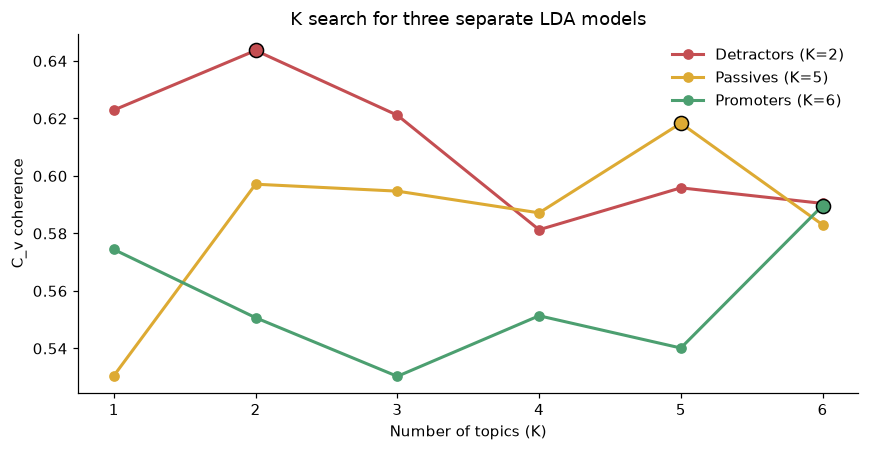

Detractors: K=2, C_v=0.6436
Passives: K=5, C_v=0.6183
Promoters: K=6, C_v=0.5897


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for g in GROUPS:
    y = [scores[g][k] for k in K_VALUES]
    ax.plot(list(K_VALUES), y, marker="o", linewidth=2, color=COLORS[g],
            label=f"{g} (K={selected[g][0]})")
    best = selected[g][0]
    ax.scatter(best, scores[g][best], s=85, color=COLORS[g], edgecolor="black", zorder=4)
ax.set(xlabel="Number of topics (K)", ylabel="C_v coherence",
       title="K search for three separate LDA models")
ax.set_xticks(list(K_VALUES)); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
for g in GROUPS:
    best = selected[g][0]
    print(f"{g}: K={best}, C_v={scores[g][best]:.4f}")


## 6. Inspect top words and representative real reviews

The top 15 weighted terms suggest a topic name but are **not sentiment evidence**. For each topic, inspect the two reviews with the highest dominant-topic probability. A review can contain other topics too. Dominant-topic counts are recorded only for a descriptive within-group prevalence chart.


In [6]:
topic_counts, representatives = {}, {}
for g in GROUPS:
    best, model = selected[g]
    dictionary, texts, corpus, indices = prepared[g]
    counts, examples = Counter(), defaultdict(list)
    for bow, row_index in zip(corpus, indices):
        topic_id, probability = max(model.get_document_topics(bow, minimum_probability=0),
                                    key=lambda pair: pair[1])
        counts[topic_id] += 1
        examples[topic_id].append((probability, rows_by_group[g][row_index]["review_text_clean"]))
    topic_counts[g] = counts
    representatives[g] = {i: sorted(examples[i], reverse=True)[:2] for i in range(best)}
    print(f"\n=== {g}: K={best} ===")
    for i in range(best):
        words = ", ".join(word for word, _ in model.show_topic(i, topn=TOP_N))
        print(f"Topic {i} ({counts[i]:,} dominant reviews): {words}")
        for probability, review in representatives[g][i]:
            print(f"  p={probability:.2f}: {review[:210]}")



=== Detractors: K=2 ===
Topic 0 (8,414 dominant reviews): phòng, khách_sạn, khách, khi, nhân_viên, tiền, h, giá, tệ, khác, hơn, người, sau, giường, dịch_vụ
  p=0.99: Thật sự quá tệ, trước đó mình đã book phòng trên agoda, mình đi 5 người lớn và đặt 2 phòng ( 1 phòng 2 người yêu cầu 1 giường - 24m2 và 1 phòng 3 người yêu cầu 2 giường - 38m2), theo thông tin giới thiệu phòng 
  p=0.99: Thật sự quá tệ, trước đó mình đã book phòng trên agoda, mình đi 5 người lớn và đặt 2 phòng ( 1 phòng 2 người yêu cầu 1 giường - 24m2 và 1 phòng 3 người yêu cầu 2 giường - 38m2), theo thông tin giới thiệu phòng 
Topic 1 (9,652 dominant reviews): phòng, khách_sạn, cũ, nhân_viên, sáng, mùi, xe, nước, bẩn, nhiều, cửa, khăn, khách, nhà, k
  p=0.99: Gia đình tôi đã thuê 5 phòng ở đây cho kỳ nghĩ Hè. Khu này chỉ tương đương nhà nghỉ, không nên gọi là khách sạn, resort hay gì cả. Thang máy, hành lang không được lau dọn thường xuyên, wc sảnh lễ tân khai như w
  p=0.99: Điểm cộng khách sạn - có vị trí cực tốt, băng


=== Passives: K=5 ===
Topic 0 (3,044 dominant reviews): sạch_sẽ, khách_sạn, phòng, nhân_viên, vị_trí, trung_tâm, đẹp, gần, biển, nhiệt_tình, thuận_tiện, tiện_nghi, giá, bãi, view
  p=0.95: Khách sạn đẹp , vị trí cách xa biển nên hơi bất tiện , view phòng hướng biển rất đẹp , vị trí ks gần trung tâm và các điểm du lịch tiện cho việc di chuyển và thăm quan du lịch
  p=0.95: - điểm cộng lớn nhất là Bể bơi của khách sạn rộng và rất sạch. - Nhân viên lễ tân nhiệt tình vui vẻ. - Vị trí rất gần trung tâm tiện đi lại. - Phòng khách sạn hơi cũ thiếu tiện nghi cần cải thiện hơn.
Topic 1 (2,128 dominant reviews): phòng, khách_sạn, khi, nước, nhân_viên, giường, đêm, bên, nóng, tối, tiếng, tầng, khách, hơn, sáng
  p=0.99: Mình đã thuê 2 phòng Deluxe Twin Ocean Front 3 đêm ở khách sạn: khi đặt phòng mình đã ghi chú rõ ràng là đặt 1 phòng 2 giường đơn và 1 phòng 1 giường đôi lớn( vì khách sạn đăng quảng cáo cũng ghi rõ loại phòng 
  p=0.97: Mình book phòng có note rõ, phòng giường lớn cuối cùng nhận


=== Promoters: K=6 ===
Topic 0 (6,773 dominant reviews): phòng, giá, ổn, tiền, sạch_sẽ, rẻ, giường, nước, hợp_lý, khách_sạn, cũ, mùi, nhỏ, hơn, sạch
  p=0.94: Đặt trên agoda thì rẻ hơn trực tiếp. Ks khá cũ cải tạo lại. Điều hòa cũ quét ak. Nhưng nước thì mạnh. Tắm sướng. Ngủ nệm lò xo cũng ổn
  p=0.93: phòng to giường to , mọi thứ đều ổn trừ cái toilet và phòng tắm nhỏ , và làm bằng kính nên cân nhắc nếu đi với nhóm bạn , hoặc người lớn tuồi , cặp đôi thì ok
Topic 1 (8,506 dominant reviews): phòng, khi, ok, nhiều, khách, gia_đình, khách_sạn, nhỏ, nhà, người, hơn, bên, nơi, đêm, xe
  p=0.96: Mình đi du lịch rất nhiều và cũng ở ks nhiều nơi. Nhưng chỉ riênh chỗ này dù đã có phòng trống khách đi xe rất mệt xin check in sớm các bạn vẫn bắt khách đợi đúng giờ mới cho check in, nếu check in sớm bắt buộc
  p=0.95: Lần thứ hai quay lại Yên Tử Legacy và vẫn rất hài lòng. Thủ tục checkin nhanh chóng, nếu bạn đến sớm và muốn nhận phòng sớm thì chỗ nghỉ sẽ xem xét phòng sớm nha. Không gian yên tĩ

## 7. Visualize weighted words in every selected topic

The bars show the top 10 LDA word weights, P(word | topic). They are **not raw counts or sentiment scores**. Read them alongside the real review examples above. The three groups have separate models, so their topic numbers do not refer to the same themes.

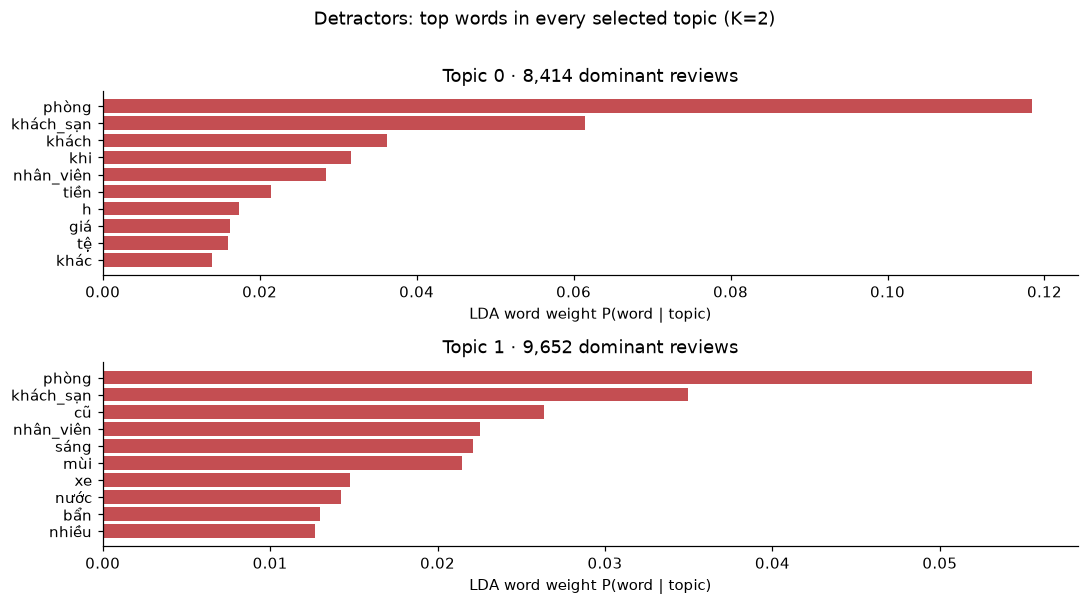

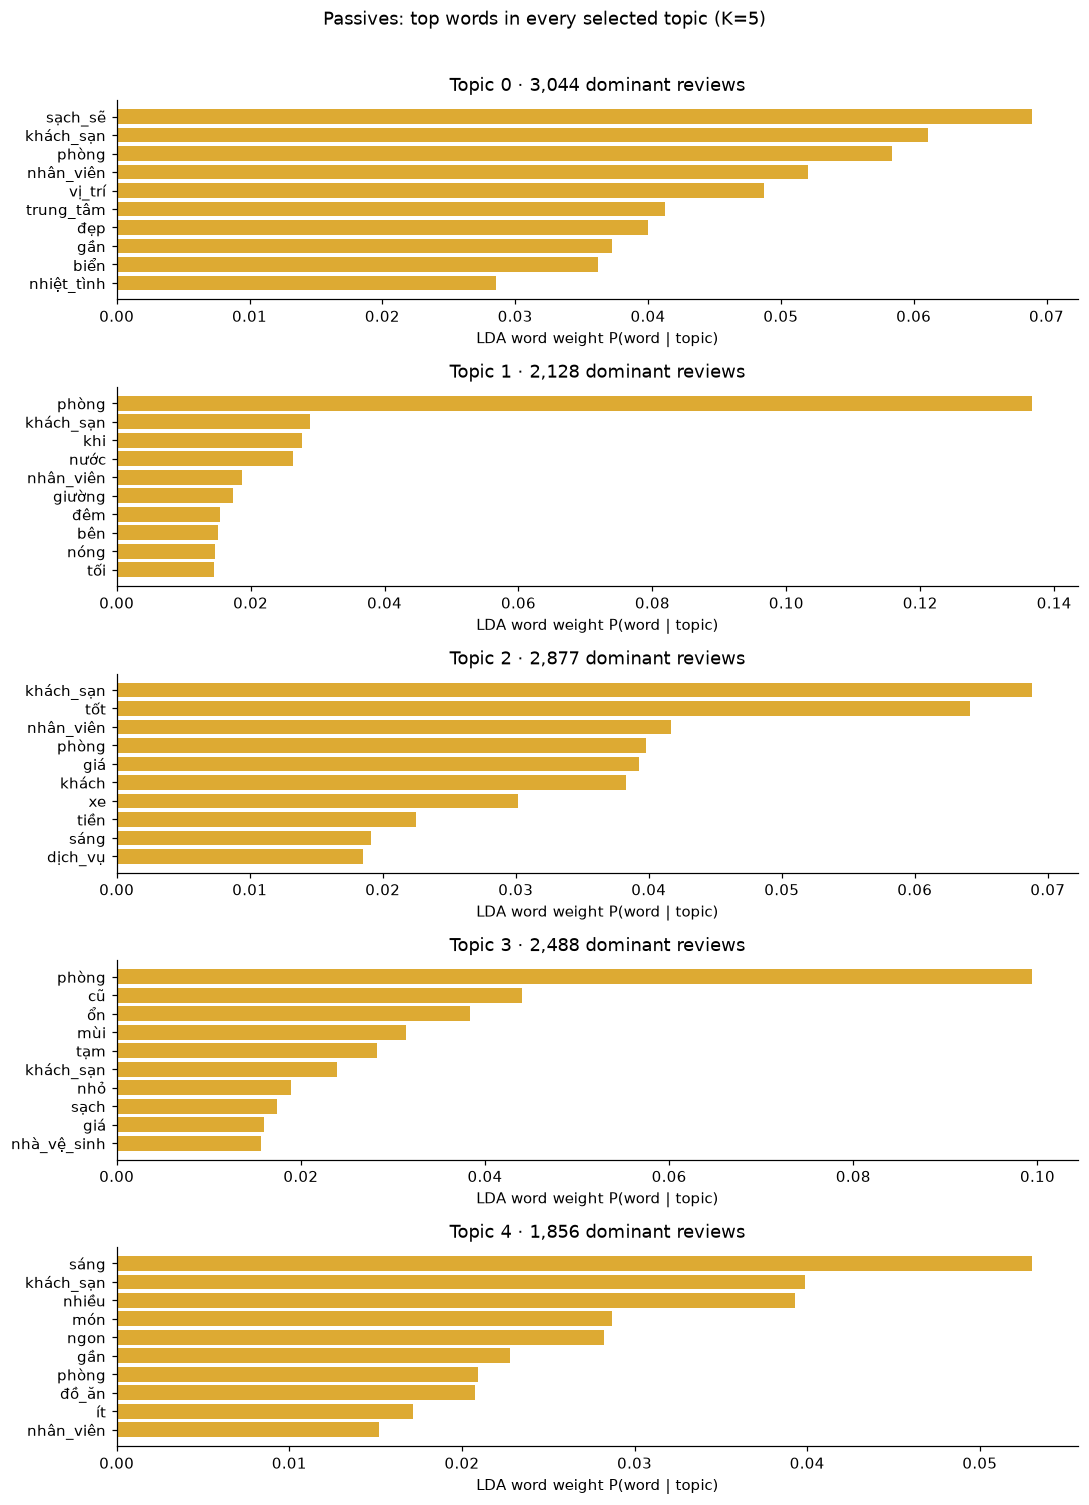

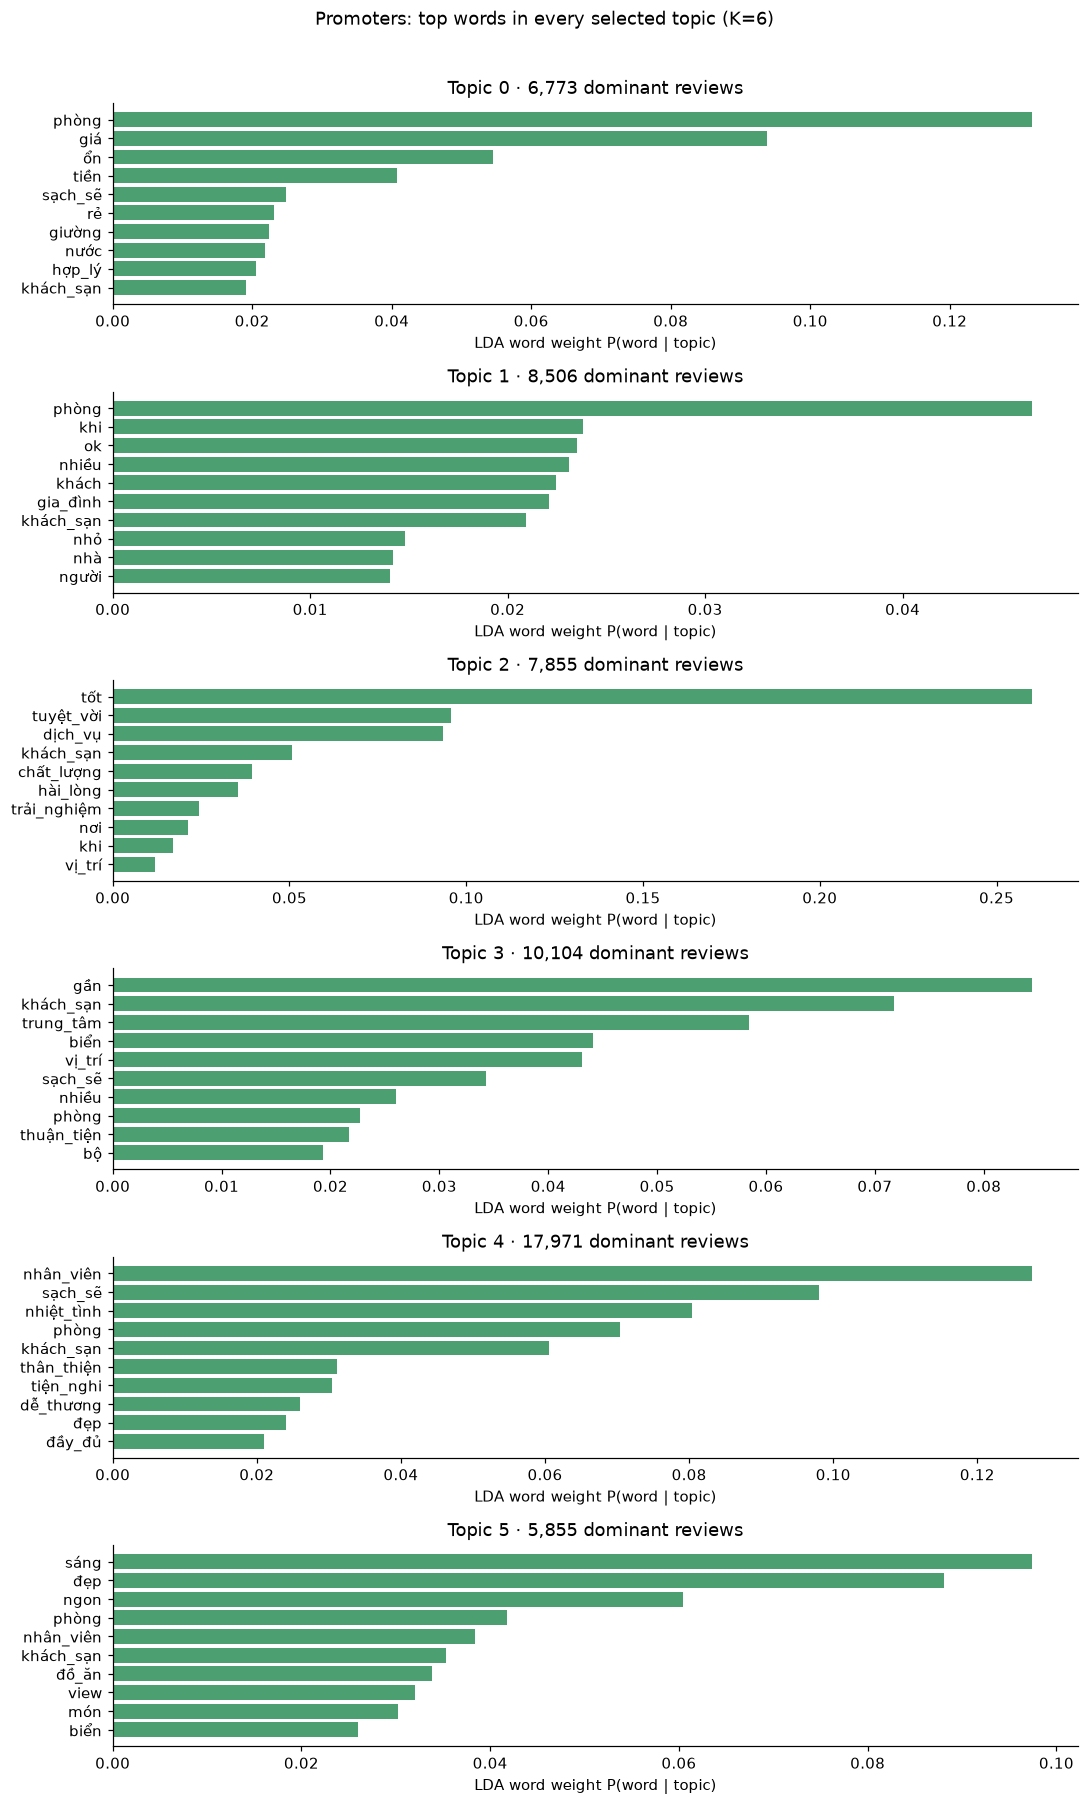

In [7]:
# Plot every selected topic, including less prevalent ones, for all three rating groups.
for group in GROUPS:
    best_k, model = selected[group]
    fig, axes = plt.subplots(best_k, 1, figsize=(10, 2.7 * best_k), squeeze=False)
    for topic_id, ax in enumerate(axes.flat):
        top_words = model.show_topic(topic_id, topn=10)[::-1]
        ax.barh([word for word, _ in top_words],
                [weight for _, weight in top_words], color=COLORS[group])
        ax.set(title=f"Topic {topic_id} · {topic_counts[group][topic_id]:,} dominant reviews",
               xlabel="LDA word weight P(word | topic)")
    fig.suptitle(f"{group}: top words in every selected topic (K={best_k})", y=1.01)
    plt.tight_layout()
    plt.show()

## 8. Word clouds for prominent topics

The paper visualizes selected group-specific topics with word clouds (Figures 5–6). Here, we choose the topic with the most **dominant reviews within each group**. Font size follows the LDA word weight P(word | topic), not corpus word frequency. These clouds are for quick inspection; the bar charts above preserve exact weights. Topic IDs remain group-specific.

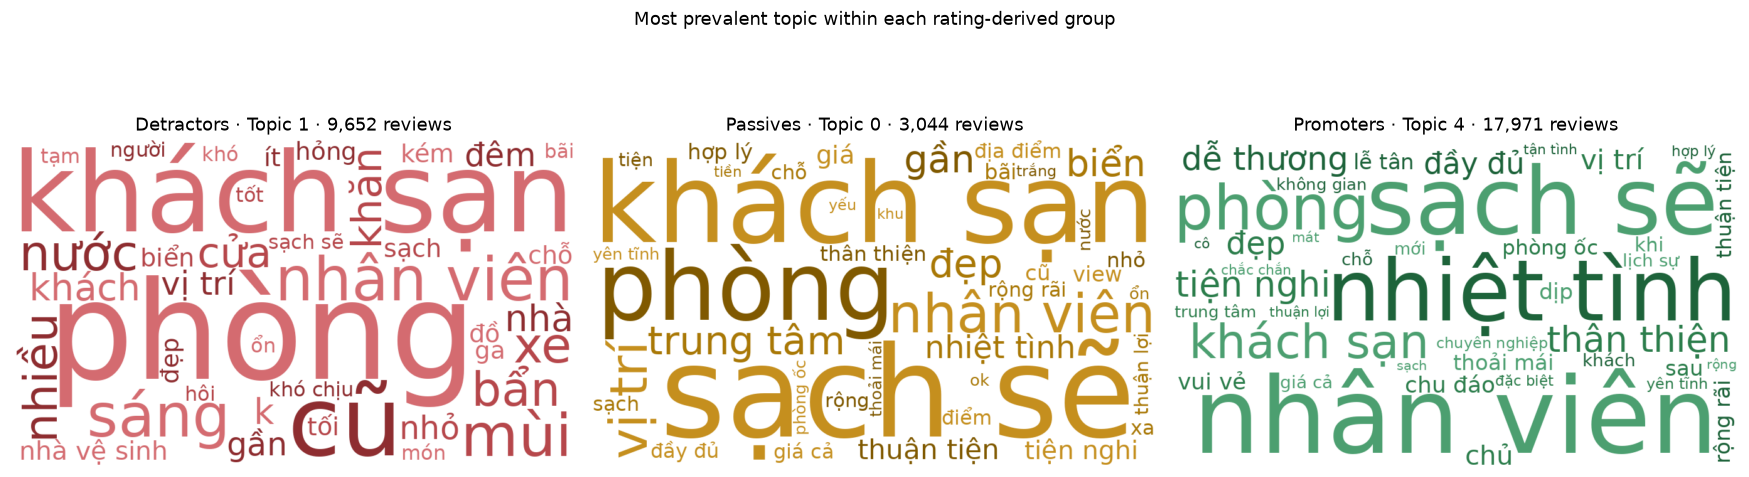

In [8]:
from matplotlib import font_manager
from wordcloud import WordCloud

font_path = font_manager.findfont("DejaVu Sans")
wordcloud_palettes = {
    "Detractors": ("#8e2d30", "#b6474b", "#d46b70"),
    "Passives": ("#805900", "#a97806", "#c58f1e"),
    "Promoters": ("#1d633a", "#2b7d4b", "#4c9f70"),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, g in zip(axes, GROUPS):
    best_k, model = selected[g]
    topic_id = max(range(best_k), key=lambda i: topic_counts[g][i])
    frequencies = {word.replace("_", " "): float(weight)
                   for word, weight in model.show_topic(topic_id, topn=40)}
    cloud = WordCloud(width=900, height=520, background_color="white",
                      font_path=font_path,
                      color_func=lambda word, font_size, position, orientation,
                                         random_state=None, **kwargs: (
                          random_state.choice(wordcloud_palettes[g])),
                      random_state=SEED, prefer_horizontal=0.9,
                      collocations=False).generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{g} · Topic {topic_id} · {topic_counts[g][topic_id]:,} reviews")
fig.suptitle("Most prevalent topic within each rating-derived group", y=1.02)
plt.tight_layout()
plt.show()

## 9. Plot within-group topic prevalence

The bar height is the fraction of reviews whose highest posterior topic is the displayed topic. **Topic IDs are group-specific**: Detractors Topic 0 cannot be equated with Promoters Topic 0. The denominator excludes documents that became empty after vocabulary filtering.


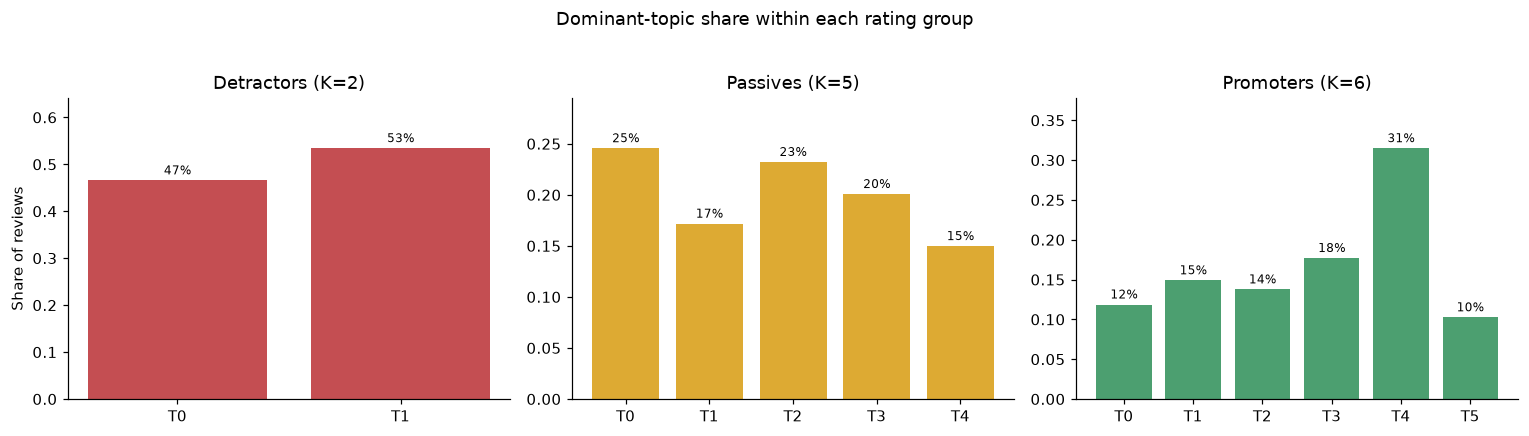

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, g in zip(axes, GROUPS):
    best = selected[g][0]
    denominator = sum(topic_counts[g].values())
    shares = [topic_counts[g][i] / denominator for i in range(best)]
    bars = ax.bar([f"T{i}" for i in range(best)], shares, color=COLORS[g])
    ax.bar_label(bars, labels=[f"{x:.0%}" for x in shares], padding=2, fontsize=8)
    ax.set_ylim(0, max(shares) * 1.2)
    ax.set(title=f"{g} (K={best})", ylabel="Share of reviews" if g == GROUPS[0] else "")
fig.suptitle("Dominant-topic share within each rating group", y=1.03)
plt.tight_layout(); plt.show()


## 10. Results table and run summary

The labels below are **provisional human interpretations** of the current model's weighted words and representative reviews. Topic IDs and labels can change when the data or model settings change. The short review is an example, not proof that every document assigned to the topic has the same meaning. Validate topic names with independent readers before making a strong customer-insight claim, as the paper did with expert labeling.

In [10]:
import re
from IPython.display import Markdown, display

# Manual names for this saved snapshot. Recheck after any retraining or data change.
TOPIC_LABELS = {
    "Detractors": {0: "Đặt phòng và dịch vụ", 1: "Tình trạng phòng và vệ sinh"},
    "Passives": {0: "Vị trí, phòng và nhân viên", 1: "Tiện nghi phòng và lưu trú",
                 2: "Chất lượng dịch vụ và giá", 3: "Phòng cũ, vệ sinh và giá",
                 4: "Ăn sáng và ăn uống"},
    "Promoters": {0: "Giá trị và tiện nghi phòng", 1: "Trải nghiệm lưu trú gia đình",
                  2: "Trải nghiệm chung và chất lượng dịch vụ",
                  3: "Vị trí và di chuyển", 4: "Nhân viên và phòng sạch",
                  5: "Ăn sáng và quang cảnh"},
}
def markdown_cell(value):
    return re.sub(r"\s+", " ", str(value)).replace("|", "\\|").strip()

for g in GROUPS:
    best_k, model = selected[g]
    denominator = sum(topic_counts[g].values())
    lines = [f"### {g}: K={best_k}, C_v={scores[g][best_k]:.4f}, {denominator:,} LDA documents",
             "", "| Topic | Tên tạm đặt | Tỷ lệ topic trội | 6 từ khóa đầu | Review đại diện (trích) |",
             "| --- | --- | ---: | --- | --- |"]
    for topic_id in range(best_k):
        label = TOPIC_LABELS.get(g, {}).get(topic_id, "Chưa gán")
        words = ", ".join(w.replace("_", " ") for w, _ in model.show_topic(topic_id, topn=6))
        review = representatives[g][topic_id][0][1] if representatives[g][topic_id] else ""
        share = topic_counts[g][topic_id] / denominator
        lines.append(f"| {topic_id} | {markdown_cell(label)} | {share:.1%} "
                     f"({topic_counts[g][topic_id]:,}) | {markdown_cell(words)} | "
                     f"{markdown_cell(review[:160])} |")
    display(Markdown("\n".join(lines)))

summary = ["### Tóm tắt ba nhóm", "",
           "| Nhóm | Review đầu vào | Review dùng cho LDA | K chọn | C_v | Topic trội nhất |",
           "| --- | ---: | ---: | ---: | ---: | --- |"]
for g in GROUPS:
    best_k, _ = selected[g]
    denominator = sum(topic_counts[g].values())
    top_topic = max(range(best_k), key=lambda i: topic_counts[g][i])
    share = topic_counts[g][top_topic] / denominator
    summary.append(f"| {g} | {group_sizes[g]:,} | {denominator:,} | {best_k} | "
                   f"{scores[g][best_k]:.4f} | {top_topic}: "
                   f"{TOPIC_LABELS.get(g, {}).get(top_topic, 'Chưa gán')} ({share:.1%}) |")
display(Markdown("\n".join(summary)))

### Detractors: K=2, C_v=0.6436, 18,066 LDA documents

| Topic | Tên tạm đặt | Tỷ lệ topic trội | 6 từ khóa đầu | Review đại diện (trích) |
| --- | --- | ---: | --- | --- |
| 0 | Đặt phòng và dịch vụ | 46.6% (8,414) | phòng, khách sạn, khách, khi, nhân viên, tiền | Thật sự quá tệ, trước đó mình đã book phòng trên agoda, mình đi 5 người lớn và đặt 2 phòng ( 1 phòng 2 người yêu cầu 1 giường - 24m2 và 1 phòng 3 người yêu cầu |
| 1 | Tình trạng phòng và vệ sinh | 53.4% (9,652) | phòng, khách sạn, cũ, nhân viên, sáng, mùi | Gia đình tôi đã thuê 5 phòng ở đây cho kỳ nghĩ Hè. Khu này chỉ tương đương nhà nghỉ, không nên gọi là khách sạn, resort hay gì cả. Thang máy, hành lang không đư |

### Passives: K=5, C_v=0.6183, 12,393 LDA documents

| Topic | Tên tạm đặt | Tỷ lệ topic trội | 6 từ khóa đầu | Review đại diện (trích) |
| --- | --- | ---: | --- | --- |
| 0 | Vị trí, phòng và nhân viên | 24.6% (3,044) | sạch sẽ, khách sạn, phòng, nhân viên, vị trí, trung tâm | Khách sạn đẹp , vị trí cách xa biển nên hơi bất tiện , view phòng hướng biển rất đẹp , vị trí ks gần trung tâm và các điểm du lịch tiện cho việc di chuyển và th |
| 1 | Tiện nghi phòng và lưu trú | 17.2% (2,128) | phòng, khách sạn, khi, nước, nhân viên, giường | Mình đã thuê 2 phòng Deluxe Twin Ocean Front 3 đêm ở khách sạn: khi đặt phòng mình đã ghi chú rõ ràng là đặt 1 phòng 2 giường đơn và 1 phòng 1 giường đôi lớn( v |
| 2 | Chất lượng dịch vụ và giá | 23.2% (2,877) | khách sạn, tốt, nhân viên, phòng, giá, khách | Mình đã ngủ ở Mai House 4 lần rồi. Khách sạn này chưa có nhiều người biết đến, nhưng khách sạn 5 sao và đặc biệt phòng khá rộng so với những ks 5 sao khác, nên |
| 3 | Phòng cũ, vệ sinh và giá | 20.1% (2,488) | phòng, cũ, ổn, mùi, tạm, khách sạn | mình thuê với tầm giá 370k/ đêm. Phòng tuy hơi cũ (giấy dán tường bong, không cửa sổ), nhưng đủ tiện nghi như máy sấy, máy nước nóng lạnh, khăn tắm, dụng cụ vệ |
| 4 | Ăn sáng và ăn uống | 15.0% (1,856) | sáng, khách sạn, nhiều, món, ngon, gần | Lần này mình ở là lần 2, mọi thứ đèu oke, ngay biển, xung quanh chỗ ăn uống nhiều. Resort nên có thêm nhiều món ăn vào menu, để khách coa thể lựa chọn ăn uống n |

### Promoters: K=6, C_v=0.5897, 57,064 LDA documents

| Topic | Tên tạm đặt | Tỷ lệ topic trội | 6 từ khóa đầu | Review đại diện (trích) |
| --- | --- | ---: | --- | --- |
| 0 | Giá trị và tiện nghi phòng | 11.9% (6,773) | phòng, giá, ổn, tiền, sạch sẽ, rẻ | Đặt trên agoda thì rẻ hơn trực tiếp. Ks khá cũ cải tạo lại. Điều hòa cũ quét ak. Nhưng nước thì mạnh. Tắm sướng. Ngủ nệm lò xo cũng ổn |
| 1 | Trải nghiệm lưu trú gia đình | 14.9% (8,506) | phòng, khi, ok, nhiều, khách, gia đình | Mình đi du lịch rất nhiều và cũng ở ks nhiều nơi. Nhưng chỉ riênh chỗ này dù đã có phòng trống khách đi xe rất mệt xin check in sớm các bạn vẫn bắt khách đợi đú |
| 2 | Trải nghiệm chung và chất lượng dịch vụ | 13.8% (7,855) | tốt, tuyệt vời, dịch vụ, khách sạn, chất lượng, hài lòng | gia đình đã có kỳ nghỉ với trải nghiệm rất tốt tại Sanddy Beach Resort, chúng tôi đã tới đây 2 lần và sẽ còn quay lại khi có dịp, và giới thiệu bạn bè biết tới |
| 3 | Vị trí và di chuyển | 17.7% (10,104) | gần, khách sạn, trung tâm, biển, vị trí, sạch sẽ | Nhà mình vừa thuê 6 phòng ở 2 đêm ở đây. Về vị trí, khách sạn không nằm trên mặt đường Trần Phú nhưng rất gần biển, đi bộ mấy phút, ở khu vực trung tâm tiện cho |
| 4 | Nhân viên và phòng sạch | 31.5% (17,971) | nhân viên, sạch sẽ, nhiệt tình, phòng, khách sạn, thân thiện | Khách sạn có phong cách thiết kế trẻ trung, hiện đại, nhìn như mới hoàn thiện. Phòng nghỉ sạch sẽ, thoáng mát và đầy đủ tiện nghi. Đội ngũ nhân viên nhiệt tình, |
| 5 | Ăn sáng và quang cảnh | 10.3% (5,855) | sáng, đẹp, ngon, phòng, nhân viên, khách sạn | Phòng sạch sẽ, nhân viên nhiệt tình, ăn sáng món ok, nhiều món. Cây xanh quang cảnh nhiều cây, bãi biển tuyệt đẹp, trong xanh. |

### Tóm tắt ba nhóm

| Nhóm | Review đầu vào | Review dùng cho LDA | K chọn | C_v | Topic trội nhất |
| --- | ---: | ---: | ---: | ---: | --- |
| Detractors | 18,120 | 18,066 | 2 | 0.6436 | 1: Tình trạng phòng và vệ sinh (53.4%) |
| Passives | 12,462 | 12,393 | 5 | 0.6183 | 0: Vị trí, phòng và nhân viên (24.6%) |
| Promoters | 57,255 | 57,064 | 6 | 0.5897 | 4: Nhân viên và phòng sạch (31.5%) |

## Interpretation boundary

This notebook follows the paper's **rating-group → separate LDA models** logic and adds the paper-style word clouds. It does not establish which aspect of a mixed review was praised or criticized. The three topic spaces differ; cross-group topic comparison requires manual alignment. The topic names above are provisional; the paper used expert labeling, which this notebook has not reproduced. The second notebook fits one common LDA space and analyzes sentiment in review clauses as a separate extension. Report denominators, C_v values, weighted words, representative reviews, and topic-label validation status.